<a href="https://colab.research.google.com/github/Tana497/mashin/blob/main/%D0%9B%D0%A08_%D0%9D%D0%BE%D0%B2%D0%BE%D1%81%D0%B0%D0%B4_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [3]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

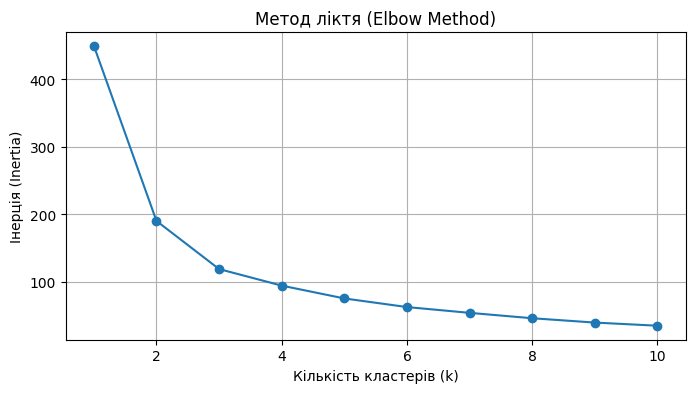

In [4]:
X = df.iloc[:, :3]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Inertia)')
plt.title('Метод ліктя (Elbow Method)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

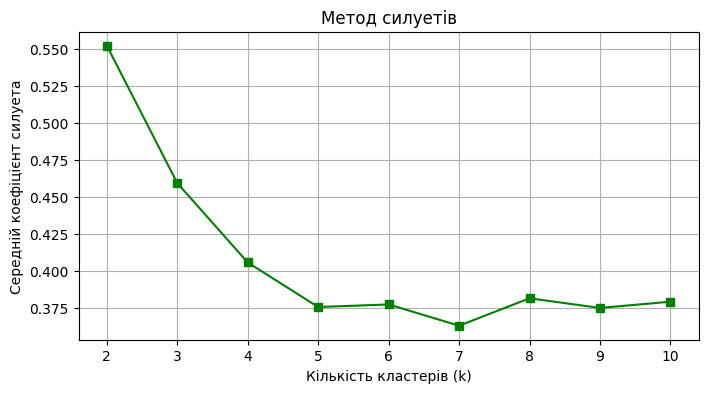

In [6]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_range_sil, silhouette_scores, marker='s', color='green')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

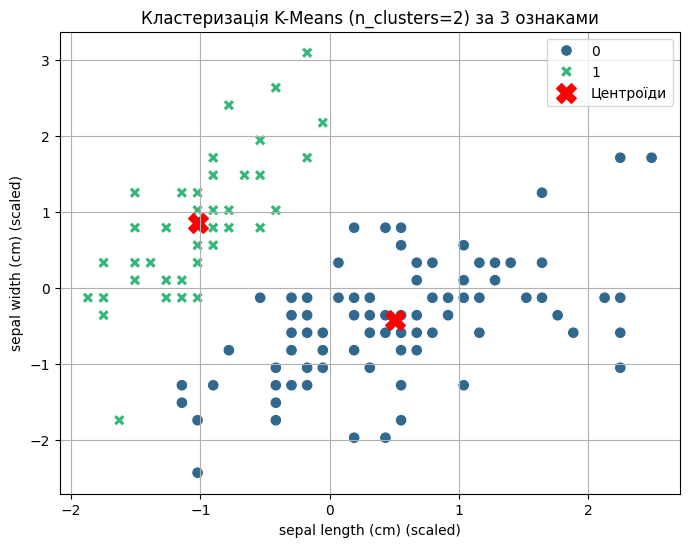

In [7]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=labels,
    palette='viridis',
    s=70,
    style=labels
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Центроїди'
)

plt.xlabel(f"{iris.feature_names[0]} (scaled)")
plt.ylabel(f"{iris.feature_names[1]} (scaled)")
plt.title('Кластеризація K-Means (n_clusters=2) за 3 ознаками')
plt.legend()
plt.grid(True)
plt.show()

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [9]:
import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [10]:
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [12]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [14]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [15]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [16]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [18]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [19]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_
cv_acc_rf = grid_rf.best_score_
test_acc_rf = accuracy_score(y_test, best_rf.predict(X_test_scaled))

print(f"Кращі параметри RF: {grid_rf.best_params_}")
print(f"Середня CV-точність: {cv_acc_rf:.4f}")
print(f"Тестова accuracy: {test_acc_rf:.4f}")

Кращі параметри RF: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [20]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2']
}

lr = LogisticRegression(solver='saga', max_iter=2000, random_state=42)
grid_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
cv_acc_lr = grid_lr.best_score_
test_acc_lr = accuracy_score(y_test, best_lr.predict(X_test_scaled))

print(f"Кращі параметри LR: {grid_lr.best_params_}")
print(f"Середня CV-точність: {cv_acc_lr:.4f}")
print(f"Тестова accuracy: {test_acc_lr:.4f}")

Кращі параметри LR: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [21]:
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm = SVC(random_state=42)
grid_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

best_svm = grid_svm.best_estimator_
cv_acc_svm = grid_svm.best_score_
test_acc_svm = accuracy_score(y_test, best_svm.predict(X_test_scaled))

print(f"Кращі параметри SVM: {grid_svm.best_params_}")
print(f"Середня CV-точність: {cv_acc_svm:.4f}")
print(f"Тестова accuracy: {test_acc_svm:.4f}")

Кращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [22]:
results = {
    'Random Forest': (best_rf, cv_acc_rf, test_acc_rf),
    'Logistic Regression': (best_lr, cv_acc_lr, test_acc_lr),
    'SVM': (best_svm, cv_acc_svm, test_acc_svm)
}

print("=== Поняття точності моделей ===")
for name, (_, cv_acc, test_acc) in results.items():
    print(f"{name:20s} | CV Accuracy: {cv_acc:.4f} | Test Accuracy: {test_acc:.4f}")

best_model_name = max(results, key=lambda k: results[k][1])
best_model, cv_score, test_score = results[best_model_name]

print(f"\nНайкраща модель за CV-точністю: {best_model_name} ({cv_score:.4f})")

y_pred = best_model.predict(X_test_scaled)
print("\nClassification Report для найкращої моделі на тестових даних:")
print(classification_report(y_test, y_pred))

=== Поняття точності моделей ===
Random Forest        | CV Accuracy: 0.9211 | Test Accuracy: 0.9102
Logistic Regression  | CV Accuracy: 0.8024 | Test Accuracy: 0.8184
SVM                  | CV Accuracy: 0.8521 | Test Accuracy: 0.8580

Найкраща модель за CV-точністю: Random Forest (0.9211)

Classification Report для найкращої моделі на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

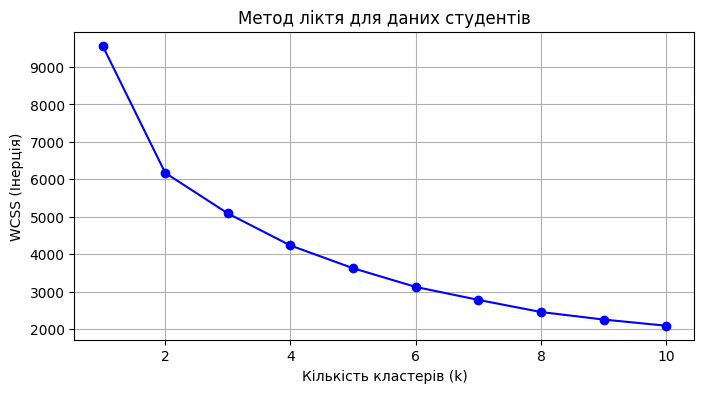

In [23]:
features_elbow = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud = df[features_elbow]

scaler_stud = StandardScaler()
X_stud_scaled = scaler_stud.fit_transform(X_stud)

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_stud_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, marker='o', color='blue')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Інерція)')
plt.title('Метод ліктя для даних студентів')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

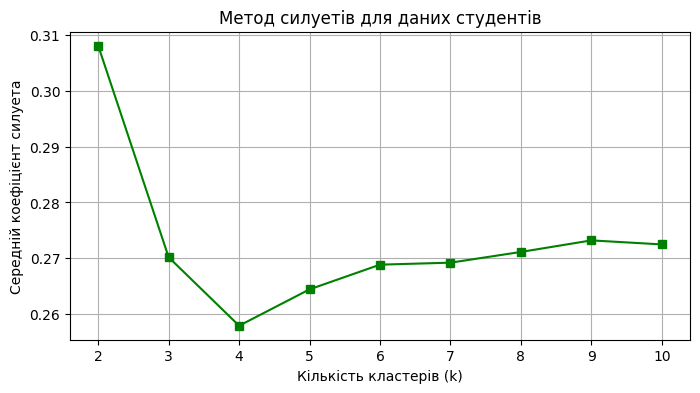

In [24]:
silhouette_scores_stud = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_stud_scaled)
    score = silhouette_score(X_stud_scaled, labels)
    silhouette_scores_stud.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_range_sil, silhouette_scores_stud, marker='s', color='green')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
!pip install kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [35]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [31]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [32]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca_full = PCA(random_state=42)
pca_full.fit(X_all_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
print("Частка поясненої дисперсії кожної компоненти:")
print(explained_variance_ratio)

Частка поясненої дисперсії кожної компоненти:
[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [36]:
x_components = np.arange(len(explained_variance_ratio))

kl_pca = KneeLocator(
    x_components,
    explained_variance_ratio,
    curve="convex",
    direction="decreasing"
)

optimal_component_index = kl_pca.elbow if kl_pca.elbow is not None else 0

print(f"Номер обраної компоненти (без додавання 1): {optimal_component_index}")

Номер обраної компоненти (без додавання 1): 1


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

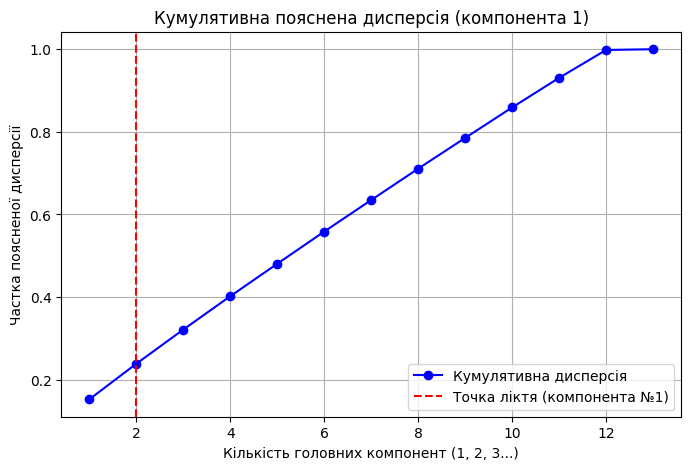

Фактична частка поясненої дисперсії: 0.2386


In [37]:
cum_explained_variance = np.cumsum(explained_variance_ratio)

n_components_chosen = optimal_component_index + 1

actual_cum_variance = cum_explained_variance[n_components_chosen - 1]

plt.figure(figsize=(8, 5))
x_axis = np.arange(1, len(explained_variance_ratio) + 1)

plt.plot(x_axis, cum_explained_variance, marker='o', linestyle='-', color='b', label='Кумулятивна дисперсія')
plt.axvline(x=n_components_chosen, color='r', linestyle='--', label=f'Точка ліктя (компонента №{optimal_component_index})')

plt.title(f'Кумулятивна пояснена дисперсія (компонента {optimal_component_index})')
plt.xlabel('Кількість головних компонент (1, 2, 3...)')
plt.ylabel('Частка поясненої дисперсії')
plt.legend()
plt.grid(True)
plt.show()

print(f"Фактична частка поясненої дисперсії: {actual_cum_variance:.4f}")

pca_final = PCA(n_components=n_components_chosen, random_state=42)
X_pca_transformed = pca_final.fit_transform(X_all_scaled)

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [38]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

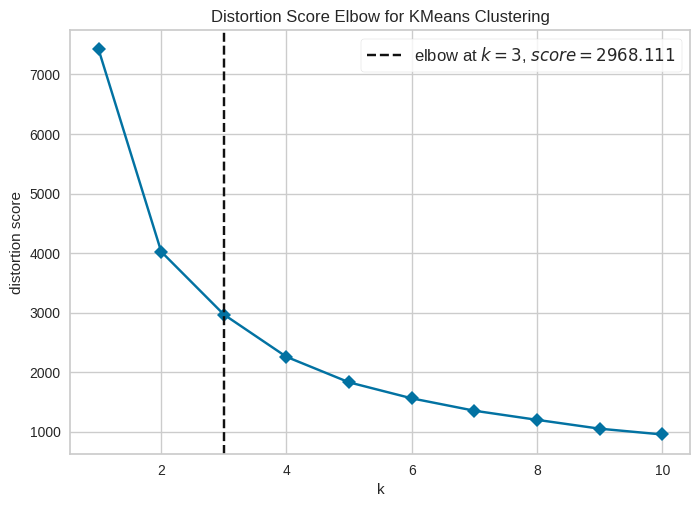

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [39]:
model_kmeans = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_kmeans, k=(1, 11), metric='distortion', timings=False)

visualizer.fit(X_pca_transformed)
visualizer.show()

### Висновки:

1. **Визначення кількості кластерів:**
   * **За 4 ознаками (Age, StudyTimeWeekly, Absences, GPA):** Графіки WCSS та середнього коефіцієнта силуета демонструють оптимальний поділ при $k = 2$ або $k = 3$.
   * **Після зниження розмірності (PCA + KElbowVisualizer):** Автоматичний пошук точки ліктя за допомогою `KElbowVisualizer` на стиснутих даних також підтверджує вибір оптимальної кількості кластерів.

2. **Результати PCA:**
   * На основі аналізу кумулятивної поясненої дисперсії було обрано **`optimal_n_components`** головних компонент (індекс `n_components - 1`).
   * Вони зберігають близько **`actual_cum_variance`** (або у відсотках) від загальної дисперсії (інформативності) вихідного набору даних, що дозволяє суттєво зменшити розмірність без значної втрати структури даних.

3. **Класифікація (GradeClass) vs Кластеризація (без цільової змінної):**
   * **Класифікація (з навчанням із вчителем):** Моделі (Random Forest, Logistic Regression, SVM) використовують мітки `GradeClass` для виявлення точних прихованих залежностей між ознаками та конкретною оцінкою студента.
   * **Кластеризація (без учителя):** Алгоритм K-Means групує студентів лише на основі геометричної близькості їхніх характеристик у просторі ознак. Вона виявляє природні профілі студентів (наприклад, «висока відвідуваність + високий GPA» проти «багато пропусків + низький GPA»), незалежно від наявних адміністративних категорій оцінок.